# Bank Marketing Subscription Prediction

## Project Overview

This project investigates how machine learning can be used to predict whether bank customers are likely to subscribe to a term deposit. It uses the **UCI Bank Marketing Dataset**, containing 45,211 customer records.

The study compares **traditional machine learning algorithms** (Logistic Regression, Random Forest, and Gradient Boosting) with **deep learning models** developed using TensorFlow/Keras.

A total of **nine experiments** were conducted, exploring data preprocessing, feature engineering, hyperparameter tuning, and neural network optimization.

Model performance is evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and average precision. The project also includes learning curves, confusion matrices, and error analysis to understand the strengths and limitations of each approach.

**Research Objective:** To identify an effective classification approach for predicting customer subscriptions and evaluate whether deep learning offers meaningful advantages over traditional machine learning.

## 1. Setup and Reproducibility

This section initializes the Python environment by importing the libraries required for data processing, machine learning, model evaluation, and visualization.

A fixed random seed is established to support reproducibility and consistency across experiments. Project directories are also created to organize datasets, trained models, experiment results, and TensorBoard logs.

In [2]:
from pathlib import Path
import os, io, json, random, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shutil

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
ROOT = Path.cwd()
DATA_DIR = ROOT / 'data' / 'raw'
OUTPUT_DIR = ROOT / 'outputs'
ARTIFACT_DIR = OUTPUT_DIR / 'models'
LOG_DIR = OUTPUT_DIR / 'tensorboard'
for folder in [DATA_DIR, OUTPUT_DIR, ARTIFACT_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print('Project directory:', ROOT)

Project directory: /content


## 2. Dataset Loading and Validation

This section loads the **UCI Bank Marketing Dataset**, which was manually downloaded and uploaded to Google Colab.

The dataset is stored in the project's `data/raw/` directory to ensure consistent file access throughout the notebook.

Validation checks are performed to verify the dataset's structure, required columns, target categories, and minimum sample size before proceeding with data analysis.

In [3]:
DATA_FILE = DATA_DIR / 'bank-full.csv'

def ensure_real_dataset(path=DATA_FILE):

    path.parent.mkdir(parents=True, exist_ok=True)

    if path.exists():
        print("Dataset found in project folder.")
        return path

    uploaded_dir = Path('/content')

    csv_files = sorted(uploaded_dir.glob('bank-full*.csv'))

    if csv_files:
        uploaded_file = csv_files[0]

        shutil.copy2(uploaded_file, path)

        print("Dataset loaded from Google Colab.")
        print("Original file:", uploaded_file)
        print("Saved to:", path)

        return path

    zip_files = sorted(uploaded_dir.glob('*.zip'))

    for zip_path in zip_files:

        try:
            with zipfile.ZipFile(zip_path, 'r') as archive:

                file_names = archive.namelist()

                csv_name = next(
                    (name for name in file_names
                     if name.endswith('bank-full.csv')),
                    None
                )

                if csv_name:
                    csv_bytes = archive.read(csv_name)

                else:
                    nested_zip = next(
                        (name for name in file_names
                         if name.endswith('bank.zip')),
                        None
                    )

                    if nested_zip is None:
                        continue

                    with zipfile.ZipFile(
                        io.BytesIO(archive.read(nested_zip))
                    ) as nested:

                        csv_name = next(
                            name for name in nested.namelist()
                            if name.endswith('bank-full.csv')
                        )

                        csv_bytes = nested.read(csv_name)

                path.write_bytes(csv_bytes)

                print("Dataset extracted from uploaded ZIP.")
                print("Saved to:", path)

                return path

        except (zipfile.BadZipFile, KeyError, StopIteration):
            continue

    raise FileNotFoundError(
        "Dataset not found! Please upload bank-full.csv "
        "or the original UCI ZIP file to Google Colab."
    )

csv_path = ensure_real_dataset()

raw = pd.read_csv(csv_path, sep=';')

print("\nDataset loaded successfully!")
print("Original data shape:", raw.shape)

assert len(raw) >= 20_000, (
    "The ORIGINAL dataset must contain at least 20,000 rows."
)

assert {'y', 'duration'}.issubset(raw.columns)

assert set(raw['y'].unique()) == {'no', 'yes'}

print("Dataset validation: PASSED")
print("Total rows:", len(raw))
print("Total columns:", len(raw.columns))

display(raw.head())

Dataset loaded from Google Colab.
Original file: /content/bank-full.csv
Saved to: /content/data/raw/bank-full.csv

Dataset loaded successfully!
Original data shape: (45211, 17)
Dataset validation: PASSED
Total rows: 45211
Total columns: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Exploratory Data Analysis (EDA)

This section explores the dataset to understand its structure, characteristics, and overall quality before model development.

The analysis examines feature data types, missing values, duplicate records, and special values such as `pdays = -1`, which indicates no previous campaign contact.

The distribution of the target variable is also examined and visualized to assess class balance and identify potential challenges for classification.

These exploratory checks help guide the preprocessing, feature engineering, and model evaluation strategies used in subsequent sections.

Columns and types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object

Null entries by column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0

Number of pdays == -1: 36954
Identical full rows: 0

Target values and class shares:
     count  proportion
y                     
no   39922       0.883
yes   5289       0.117


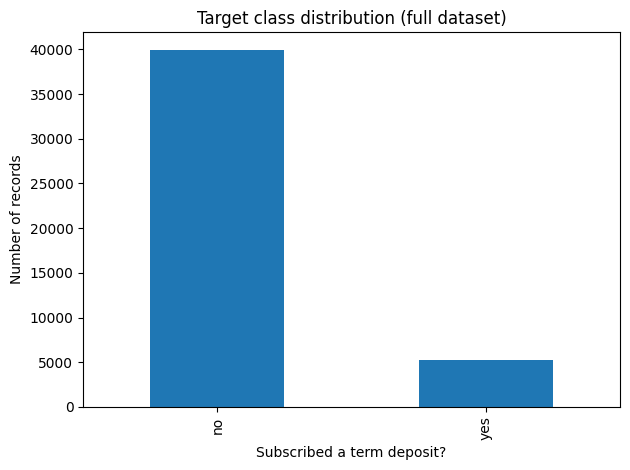

In [4]:
print('Columns and types:')
print(raw.dtypes.to_string())
print('\nNull entries by column:')
print(raw.isna().sum().sort_values(ascending=False).to_string())
print('\nNumber of pdays == -1:', int((raw['pdays'] == -1).sum()))
print('Identical full rows:', int(raw.duplicated().sum()))
print('\nTarget values and class shares:')
print(pd.DataFrame({'count':raw['y'].value_counts(),
                    'proportion':raw['y'].value_counts(normalize=True).round(3)}))
raw['y'].value_counts().plot(kind='bar', title='Target class distribution (full dataset)')
plt.xlabel('Subscribed a term deposit?'); plt.ylabel('Number of records')
plt.tight_layout(); plt.show()

## 4. Feature Selection and Dataset Splitting

This section prepares the dataset for model development by selecting relevant input features and separating the target variable.

The variables `duration`, `day`, and `month` are excluded to reduce potential data leakage and reliance on campaign-specific information. The target variable `y` is converted into binary labels for classification.

The dataset is divided into **training (70%), validation (15%), and testing (15%)** subsets using stratified sampling to preserve the target class distribution.

A fixed random seed ensures reproducibility, while the test dataset is reserved for independent final evaluation after model selection and optimization.

In [5]:
DROP_INPUTS = ['duration', 'day', 'month']
X = raw.drop(columns=['y'] + DROP_INPUTS)
y = (raw['y'] == 'yes').astype('int32')

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=(0.15 / 0.85),
    random_state=SEED, stratify=y_dev)
print('Original:', len(raw), '| train:', len(X_train),
      '| validation:', len(X_val), '| test:', len(X_test))
print('Train positives:', round(y_train.mean(), 4))
print('Validation positives:', round(y_val.mean(), 4))
print('Test positives:', round(y_test.mean(), 4))

Original: 45211 | train: 31647 | validation: 6782 | test: 6782
Train positives: 0.117
Validation positives: 0.1169
Test positives: 0.1169


## 5. Feature Engineering and Preprocessing

This section prepares the dataset for model training through feature engineering and preprocessing.

Two additional features, `contacted_before` and `log_campaign`, are created to represent previous customer contact history and transform campaign contact counts. The `pdays` variable is also processed to handle values indicating no previous contact.

Numerical features undergo median imputation and standardization, while categorical features are processed using most-frequent imputation and one-hot encoding.

All preprocessing steps are implemented using **Scikit-learn pipelines** to ensure consistent data transformation and prevent data leakage.

In [6]:
def make_features(X_frame, engineered=False):
    x = X_frame.copy()
    x['pdays'] = x['pdays'].replace(-1, np.nan)
    if engineered:
        x['contacted_before'] = (x['previous'] > 0).astype('int32')
        x['log_campaign'] = np.log1p(x['campaign'])
    return x

def make_preprocessor(X_frame):
    num_cols = X_frame.select_dtypes(include=np.number).columns.tolist()
    cat_cols = X_frame.select_dtypes(exclude=np.number).columns.tolist()
    num_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer([
        ('numeric', num_pipe, num_cols),
        ('categorical', cat_pipe, cat_cols),
    ], sparse_threshold=0.0)

print('Raw features:', X_train.shape[1])
print('Engineered features:', make_features(X_train, True).shape[1])

Raw features: 13
Engineered features: 15


## 6. Evaluation Metrics and Experiment Logging

This section establishes the evaluation framework used to assess and compare machine learning and deep learning models.

Six evaluation metrics are implemented: **accuracy, precision, recall, F1-score, ROC-AUC, and average precision (AP)**. These metrics provide a comprehensive assessment of model performance, particularly for imbalanced classification problems.

An experiment logging system is developed to record model configurations, hyperparameters, training and validation dataset sizes, and evaluation metrics. Results are automatically saved in CSV format to support systematic comparison and reproducibility.

A majority-class baseline classifier is also implemented to provide a reference point for evaluating subsequent models.

In [7]:
results = []
trained_ml_models = {}
trained_dl_models = {}

def evaluate_probabilities(y_true, p, threshold=0.50):
    pred = (np.asarray(p) >= threshold).astype('int32')
    return dict(accuracy=accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred, zero_division=0),
                f1=f1_score(y_true, pred, zero_division=0),
                roc_auc=roc_auc_score(y_true, p),
                pr_auc=average_precision_score(y_true, p))

def add_experiment(run_id, family, engineered, settings, probas, notes):
    scores = evaluate_probabilities(y_val, probas)
    row = {'run_id': run_id, 'family': family,
           'feature_engineering': engineered,
           'settings': json.dumps(settings, sort_keys=True),
           'train_rows': len(X_train), 'val_rows': len(X_val),
           'test_rows_held_out': len(X_test),
           **{'val_' + k: round(v, 5) for k, v in scores.items()},
           'observation_to_verify': notes}
    results.append(row)
    pd.DataFrame(results).to_csv(OUTPUT_DIR / 'experiment_results.csv', index=False)
    print(run_id, ':', {k: round(v, 4) for k, v in scores.items()})

majority = DummyClassifier(strategy='most_frequent', random_state=SEED)
majority.fit(X_train, y_train)
majority_probs = majority.predict_proba(X_val)[:, 1]
print('Majority-class benchmark (not counted among 9 model experiments):')
print(evaluate_probabilities(y_val, majority_probs))

Majority-class benchmark (not counted among 9 model experiments):
{'accuracy': 0.8830728398702448, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': np.float64(0.5), 'pr_auc': np.float64(0.11692716012975524)}


## 7. Traditional Machine Learning Experiments

This section implements and evaluates **six traditional machine learning experiments** using Scikit-learn to predict customer subscriptions.

Three algorithms are explored: **Logistic Regression, Random Forest, and Gradient Boosting**. Different model configurations are tested to examine the effects of hyperparameter tuning, feature engineering, and class balancing.

Each model is trained on the training dataset and evaluated using the validation dataset. The experiments are conducted through Scikit-learn pipelines to ensure consistent preprocessing and prevent data leakage.

Model configurations, training times, and evaluation metrics are recorded to support systematic comparison and reproducibility.

In [8]:
import time

def run_ml(run_id, estimator, engineered, notes):
    xtr = make_features(X_train, engineered)
    xva = make_features(X_val, engineered)
    model = Pipeline([
        ('prep', make_preprocessor(xtr)),
        ('model', estimator)
    ])
    start = time.perf_counter()
    model.fit(xtr, y_train)
    sec = time.perf_counter() - start
    probas = model.predict_proba(xva)[:, 1]
    settings = {'model': type(estimator).__name__,
                **estimator.get_params(deep=False), 'training_seconds': round(sec, 2)}
    add_experiment(run_id, 'traditional ML', engineered, settings,
                   probas, notes)
    trained_ml_models[run_id] = model
    return model

run_ml('E1_LR_base', LogisticRegression(max_iter=1000, random_state=SEED),
       False, 'Linear baseline: compare precision/recall with majority baseline')
run_ml('E2_LR_tuned', LogisticRegression(C=0.2, max_iter=1000, random_state=SEED),
       True, 'L2 regularization and engineered features; test E6 for isolation')
run_ml('E3_RF_base', RandomForestClassifier(
    n_estimators=120, max_depth=12, min_samples_leaf=2,
    random_state=SEED, n_jobs=-1),
    False, 'Forest baseline; inspect whether variance is lower than E4')
run_ml('E4_RF_tuned', RandomForestClassifier(
    n_estimators=220, max_depth=16, min_samples_leaf=4,
    class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
    True, 'More trees, adjusted depth, class weights; assess precision/recall tradeoff')
run_ml('E5_HGB', HistGradientBoostingClassifier(
    max_iter=180, learning_rate=0.07, max_leaf_nodes=20,
    l2_regularization=0.1, random_state=SEED),
    True, 'Gradient boosting compared to linear model and forest')
run_ml('E6_LR_feature_ablation', LogisticRegression(
    C=1.0, max_iter=1000, random_state=SEED),
    True, 'Same logistic hyperparameters as E1, but engineered features added')

E1_LR_base : {'accuracy': 0.8924, 'precision': 0.6507, 'recall': 0.1715, 'f1': 0.2715, 'roc_auc': np.float64(0.7498), 'pr_auc': np.float64(0.3666)}
E2_LR_tuned : {'accuracy': 0.8924, 'precision': 0.6522, 'recall': 0.1702, 'f1': 0.27, 'roc_auc': np.float64(0.7498), 'pr_auc': np.float64(0.3671)}
E3_RF_base : {'accuracy': 0.8919, 'precision': 0.6456, 'recall': 0.1677, 'f1': 0.2663, 'roc_auc': np.float64(0.7631), 'pr_auc': np.float64(0.3859)}
E4_RF_tuned : {'accuracy': 0.8206, 'precision': 0.3265, 'recall': 0.5032, 'f1': 0.396, 'roc_auc': np.float64(0.7649), 'pr_auc': np.float64(0.3912)}
E5_HGB : {'accuracy': 0.8919, 'precision': 0.6316, 'recall': 0.1816, 'f1': 0.2821, 'roc_auc': np.float64(0.7644), 'pr_auc': np.float64(0.3829)}
E6_LR_feature_ablation : {'accuracy': 0.8924, 'precision': 0.6507, 'recall': 0.1715, 'f1': 0.2715, 'roc_auc': np.float64(0.75), 'pr_auc': np.float64(0.3673)}


Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0.0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'balance', 'campaign',
                                                   'pdays', 'previous',
                                                   'contacted_before',
                                                   'log_campaign']),
                                                 ('categorical',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'poutcome'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

## 8. Deep Learning with TensorFlow/Keras

This section implements and evaluates **three deep learning experiments** using TensorFlow and Keras to predict customer subscriptions.

The dataset is prepared for neural network training through feature engineering, numerical transformation, and categorical encoding. TensorFlow's `tf.data` API is used to create efficient data pipelines with batching, shuffling, and prefetching.

Three neural network architectures are developed using the **Keras Sequential API**, exploring different hidden layers, dropout rates, L2 regularization, batch normalization, and learning rates.

Early stopping is implemented to monitor validation performance and reduce overfitting. Training histories and model configurations are recorded using **TensorBoard and CSV logs** to support experiment tracking and reproducibility.

In [9]:
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    print('Exact TensorFlow op determinism not available; random seeds are set.')

Xtr_eng = make_features(X_train, engineered=True)
Xva_eng = make_features(X_val, engineered=True)
Xte_eng = make_features(X_test, engineered=True)

dl_preprocessor = make_preprocessor(Xtr_eng)
Xtr_nn = dl_preprocessor.fit_transform(Xtr_eng).astype('float32')
Xva_nn = dl_preprocessor.transform(Xva_eng).astype('float32')
Xte_nn = dl_preprocessor.transform(Xte_eng).astype('float32')

def ds_train(x, labels, batch_size=256):
    return (tf.data.Dataset.from_tensor_slices((x, np.asarray(labels, dtype='float32')))
            .shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
            .batch(batch_size).prefetch(tf.data.AUTOTUNE))

def ds_eval(x, labels, batch_size=256):
    return (tf.data.Dataset.from_tensor_slices((x, np.asarray(labels, dtype='float32')))
            .batch(batch_size).prefetch(tf.data.AUTOTUNE))

train_ds = ds_train(Xtr_nn, y_train)
val_ds = ds_eval(Xva_nn, y_val)
test_ds = ds_eval(Xte_nn, y_test)
print('NN input dimension after encoding:', Xtr_nn.shape[1])

NN input dimension after encoding: 39


In [10]:
def build_dense_network(n_inputs, hidden=(64, 32), dropout=0.0,
                        l2_strength=0.0, batch_norm=False, lr=0.001):
    layers = [tf.keras.layers.Input(shape=(n_inputs,))]
    for width in hidden:
        layers.append(tf.keras.layers.Dense(
            width, activation=None if batch_norm else 'relu',
            kernel_regularizer=tf.keras.regularizers.l2(l2_strength)))
        if batch_norm:
            layers.extend([tf.keras.layers.BatchNormalization(),
                           tf.keras.layers.Activation('relu')])
        if dropout > 0:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation='sigmoid'))
    network = tf.keras.Sequential(layers)
    network.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                    loss='binary_crossentropy',
                    metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'),
                             tf.keras.metrics.AUC(name='roc_auc', curve='ROC'),
                             tf.keras.metrics.AUC(name='pr_auc', curve='PR')])
    return network

history_logs = {}

def run_dl(run_id, settings, notes, epochs=25):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_dense_network(Xtr_nn.shape[1], **settings)
    run_dir = LOG_DIR / run_id
    run_dir.mkdir(parents=True, exist_ok=True)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_roc_auc', mode='max', patience=5,
            restore_best_weights=True),
        tf.keras.callbacks.TensorBoard(log_dir=str(run_dir), histogram_freq=0),
        tf.keras.callbacks.CSVLogger(str(run_dir / 'history.csv')),
    ]
    t0 = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds,
                        epochs=epochs, callbacks=callbacks, verbose=1)
    elapsed = time.perf_counter() - t0
    val_prob = model.predict(Xva_nn, batch_size=256, verbose=0).reshape(-1)
    add_experiment(run_id, 'deep learning', True,
                   {**settings, 'max_epochs': epochs,
                    'epochs_run': len(history.history['loss']),
                    'training_seconds': round(elapsed, 2)},
                   val_prob, notes)
    trained_dl_models[run_id] = model
    history_logs[run_id] = history.history

run_dl('D1_Dense_basic',
       dict(hidden=(64, 32), dropout=0.0, l2_strength=0.0,
            batch_norm=False, lr=0.001),
       'Two hidden layers with no explicit regularization')
run_dl('D2_Dense_regularized',
       dict(hidden=(128, 64), dropout=0.30, l2_strength=0.0001,
            batch_norm=False, lr=0.001),
       'Larger network plus dropout/L2; compare generalization gap')
run_dl('D3_Dense_BN',
       dict(hidden=(128, 64, 32), dropout=0.20, l2_strength=0.0001,
            batch_norm=True, lr=0.0005),
       'Deeper architecture, batch normalization, lower learning rate')

Epoch 1/25
124/124 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8785 - loss: 0.3619 - pr_auc: 0.1691 - roc_auc: 0.6366 - val_accuracy: 0.8868 - val_loss: 0.3207 - val_pr_auc: 0.3357 - val_roc_auc: 0.7263
Epoch 2/25
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8902 - loss: 0.3118 - pr_auc: 0.3680 - roc_auc: 0.7444 - val_accuracy: 0.8918 - val_loss: 0.3090 - val_pr_auc: 0.3716 - val_roc_auc: 0.7520
Epoch 3/25
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8930 - loss: 0.3058 - pr_auc: 0.3832 - roc_auc: 0.7568 - val_accuracy: 0.8922 - val_loss: 0.3059 - val_pr_auc: 0.3790 - val_roc_auc: 0.7587
Epoch 4/25
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8937 - loss: 0.3041 - pr_auc: 0.3885 - roc_auc: 0.7602 - val_accuracy: 0.8935 - val_loss: 0.3058 - val_pr_auc: 0.3795 - val_roc_auc: 0.7596
Epoch 5/25
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8943 - loss: 0.3027 - pr_auc: 0.3955 - roc_auc: 0.7630 - val_accuracy: 0.8924 - val_loss: 0.3048 - val_pr_auc:

## 9. Model Comparison and Learning Curves

This section compares the performance of all **nine experiments**, consisting of six traditional machine learning models and three deep learning models.

The models are ranked using validation ROC-AUC, while additional evaluation metrics are presented to support a comprehensive performance comparison.

A comparison chart is generated to visualize differences in predictive performance across the experiments.

Learning curves are also plotted for the three neural networks, showing training and validation loss across epochs. These visualizations help assess model convergence, generalization, and potential overfitting.

The comparison tables and figures are saved for documentation and inclusion in the final report.

,run_id,family,feature_engineering,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_pr_auc,settings
7,D2_Dense_regularized,deep learning,True,0.89339,0.66355,0.17907,0.28203,0.77207,0.39310,"{""batch_norm"": false, ""dropout"": 0.3, ""epochs_..."
8,D3_Dense_BN,deep learning,True,0.89207,0.62656,0.19042,0.29207,0.77049,0.38841,"{""batch_norm"": true, ""dropout"": 0.2, ""epochs_r..."
6,D1_Dense_basic,deep learning,True,0.89310,0.64912,0.18663,0.28991,0.76783,0.38193,"{""batch_norm"": false, ""dropout"": 0.0, ""epochs_..."
3,E4_RF_tuned,traditional ML,True,0.82055,0.32651,0.50315,0.39603,0.76490,0.39119,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""class_w..."
4,E5_HGB,traditional ML,True,0.89192,0.63158,0.18159,0.28208,0.76442,0.38289,"{""categorical_features"": ""from_dtype"", ""class_..."
2,E3_RF_base,traditional ML,False,0.89192,0.64563,0.16772,0.26627,0.76315,0.38586,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""class_w..."
5,E6_LR_feature_ablation,traditional ML,True,0.89236,0.65072,0.17150,0.27146,0.75001,0.36733,"{""C"": 1.0, ""class_weight"": null, ""dual"": false..."
0,E1_LR_base,traditional ML,False,0.89236,0.65072,0.17150,0.27146,0.74978,0.36660,"{""C"": 1.0, ""class_weight"": null, ""dual"": false..."
1,E2_LR_tuned,traditional ML,True,0.89236,0.65217,0.17024,0.27000,0.74976,0.36705,"{""C"": 0.2, ""class_weight"": null, ""dual"": false..."


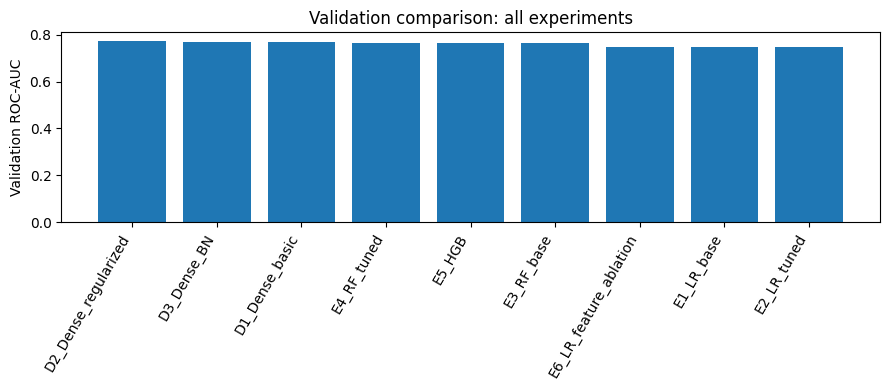

In [11]:
summary = pd.DataFrame(results).sort_values('val_roc_auc', ascending=False)
display(summary[['run_id', 'family', 'feature_engineering',
                 'val_accuracy', 'val_precision', 'val_recall',
                 'val_f1', 'val_roc_auc', 'val_pr_auc', 'settings']])
summary.to_csv(OUTPUT_DIR / 'experiment_results_sorted.csv', index=False)

plt.figure(figsize=(9, 4))
plt.bar(summary['run_id'], summary['val_roc_auc'])
plt.xticks(rotation=60, ha='right')
plt.ylabel('Validation ROC-AUC')
plt.title('Validation comparison: all experiments')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'validation_model_comparison.png', dpi=160)
plt.show()

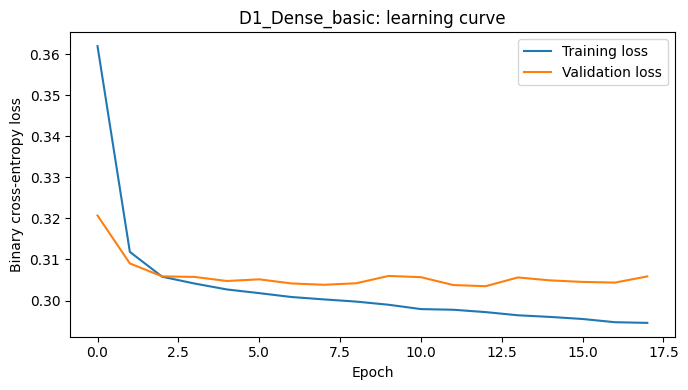

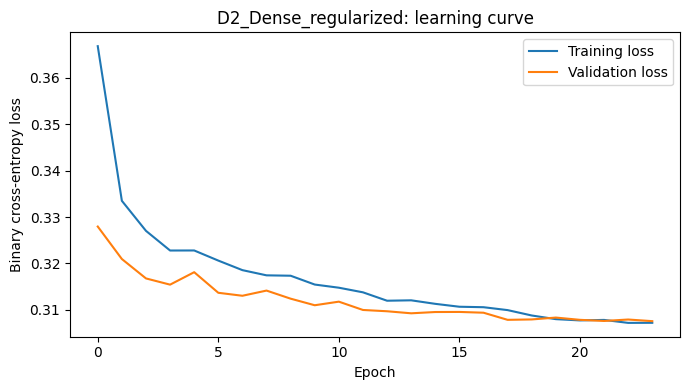

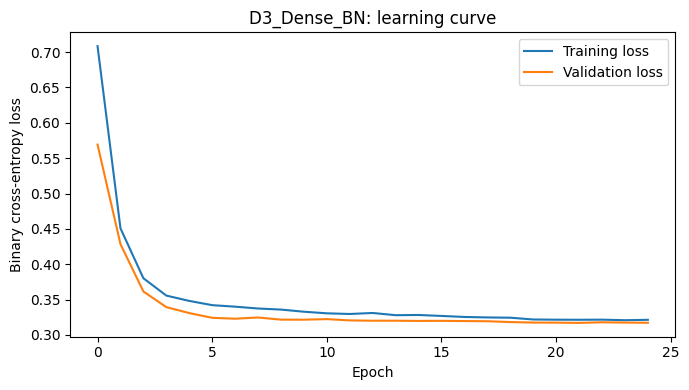

To inspect run-level logs in a terminal: tensorboard --logdir outputs/tensorboard


In [12]:
for name, hist in history_logs.items():
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(hist['loss'], label='Training loss')
    ax.plot(hist['val_loss'], label='Validation loss')
    ax.set_title(f'{name}: learning curve')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Binary cross-entropy loss')
    ax.legend(); fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'{name}_learning_curve.png', dpi=160)
    plt.show()

print('To inspect run-level logs in a terminal: tensorboard --logdir outputs/tensorboard')

## 10. Best Model Selection and Threshold Optimization

This section identifies the best-performing traditional machine learning model and deep learning model based on their **validation ROC-AUC scores**.

The selected models are further optimized by adjusting their classification probability thresholds. Instead of relying solely on the default threshold of 0.50, the optimal thresholds are determined by maximizing the F1-score on the validation dataset.

This process allows the models to balance precision and recall more effectively, particularly when working with imbalanced data.

Model selection and threshold optimization are performed exclusively on validation data to preserve the independence of the final test dataset.

In [13]:
ml_rows = [r for r in results if r['family'] == 'traditional ML']
dl_rows = [r for r in results if r['family'] == 'deep learning']
best_ml_id = max(ml_rows, key=lambda r: r['val_roc_auc'])['run_id']
best_dl_id = max(dl_rows, key=lambda r: r['val_roc_auc'])['run_id']
best_ml = trained_ml_models[best_ml_id]
best_dl = trained_dl_models[best_dl_id]

ml_is_engineered = next(r['feature_engineering'] for r in ml_rows
                        if r['run_id'] == best_ml_id)
ml_val_prob = best_ml.predict_proba(
    make_features(X_val, ml_is_engineered))[:, 1]
dl_val_prob = best_dl.predict(Xva_nn, batch_size=256, verbose=0).reshape(-1)

def f1_best_threshold(labels, probabilities):
    prec, rec, thresholds = precision_recall_curve(labels, probabilities)
    f1_candidates = 2 * prec[:-1] * rec[:-1] / (
        prec[:-1] + rec[:-1] + 1e-12)
    return float(thresholds[np.argmax(f1_candidates)]) if len(thresholds) else 0.5

ml_threshold = f1_best_threshold(y_val, ml_val_prob)
dl_threshold = f1_best_threshold(y_val, dl_val_prob)
print('Best classical ML:', best_ml_id, 'threshold:', round(ml_threshold, 3))
print('Best deep learning:', best_dl_id, 'threshold:', round(dl_threshold, 3))

Best classical ML: E4_RF_tuned threshold: 0.551
Best deep learning: D2_Dense_regularized threshold: 0.251


## 11. Final Model Evaluation and Error Analysis

This section evaluates the selected traditional machine learning and deep learning models using the independent test dataset.

Both models are assessed using the default classification threshold and their validation-optimized thresholds. Performance is measured using accuracy, precision, recall, F1-score, ROC-AUC, and average precision.

Confusion matrices are generated to examine correct predictions, false positives, and false negatives. ROC and precision-recall curves are also plotted to compare the models across different classification thresholds.

An additional error analysis examines false-negative rates across customer occupational categories to identify variations in model performance between groups.

The evaluation results, confusion matrices, and performance curves are saved for further analysis and inclusion in the final report.

,run_id,threshold_policy,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,E4_RF_tuned,default_0.5,0.50000,0.822766,0.330290,0.501892,0.398398,0.755781,0.381976
1,E4_RF_tuned,validation_tuned,0.55133,0.843114,0.360453,0.441362,0.396825,0.755781,0.381976
2,D2_Dense_regularized,default_0.5,0.50000,0.892215,0.640909,0.177806,0.278381,0.756723,0.371371
3,D2_Dense_regularized,validation_tuned,0.25149,0.869213,0.426563,0.344262,0.381019,0.756723,0.371371


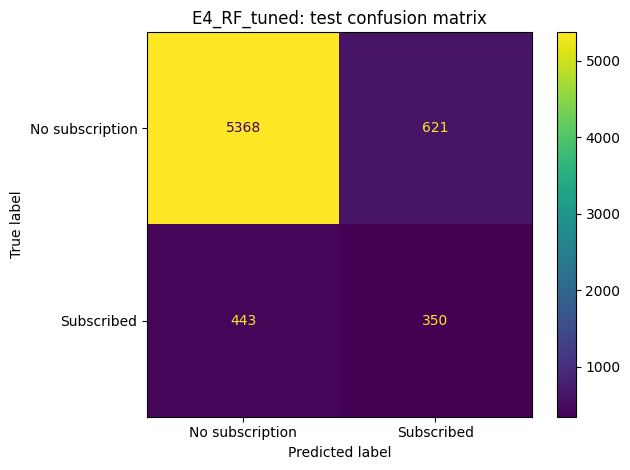

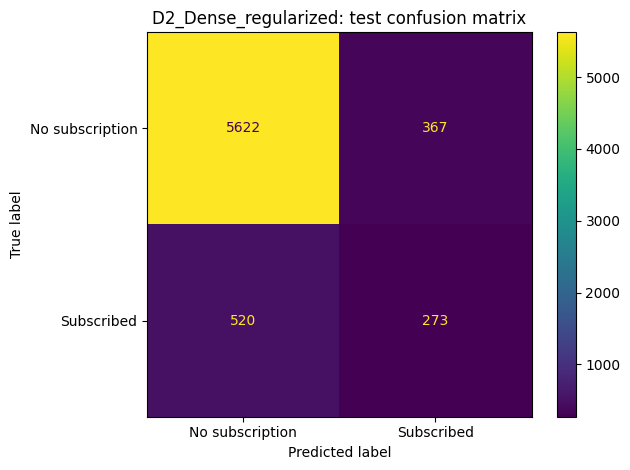

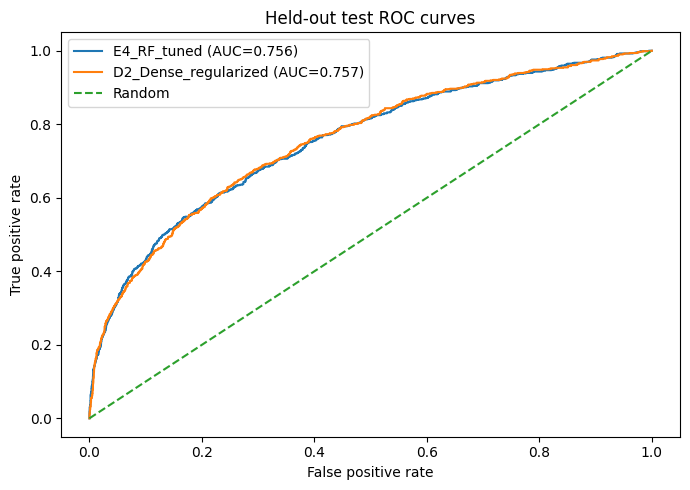

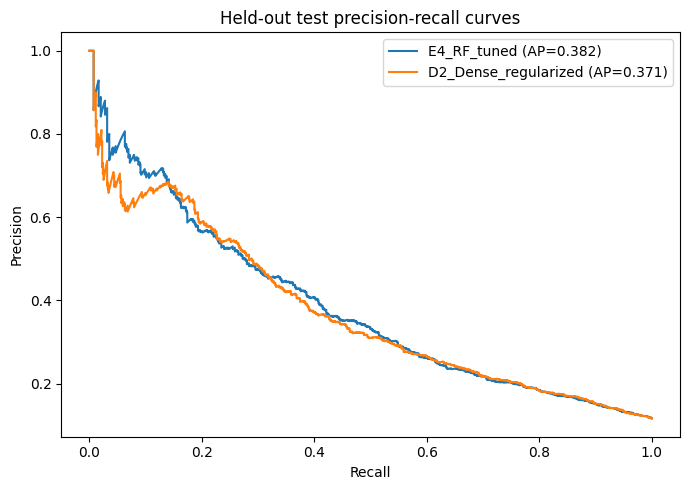

In [14]:
ml_test_prob = best_ml.predict_proba(make_features(X_test, ml_is_engineered))[:, 1]
dl_test_prob = best_dl.predict(Xte_nn, batch_size=256, verbose=0).reshape(-1)

comparisons = {
    best_ml_id: (ml_test_prob, ml_threshold),
    best_dl_id: (dl_test_prob, dl_threshold),
}
final_rows = []
for run_id, (prob, selected_threshold) in comparisons.items():
    for threshold_name, threshold in [('default_0.5', 0.50),
                                      ('validation_tuned', selected_threshold)]:
        final_rows.append({'run_id': run_id,
                           'threshold_policy': threshold_name,
                           'threshold': round(threshold, 5),
                           **evaluate_probabilities(y_test, prob, threshold)})
final_table = pd.DataFrame(final_rows)
display(final_table)
final_table.to_csv(OUTPUT_DIR / 'final_test_results.csv', index=False)

# Independent confusion matrix figure for each winning model.
for name, (prob, threshold) in comparisons.items():
    pred = (prob >= threshold).astype(int)
    disp = ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred),
        display_labels=['No subscription', 'Subscribed'])
    disp.plot(values_format='d')
    plt.title(f'{name}: test confusion matrix')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{name}_confusion_matrix.png', dpi=160)
    plt.show()

plt.figure(figsize=(7, 5))
for name, (prob, _) in comparisons.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random')
plt.title('Held-out test ROC curves'); plt.xlabel('False positive rate')
plt.ylabel('True positive rate'); plt.legend(); plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'test_roc_curves.png', dpi=160)
plt.show()

plt.figure(figsize=(7, 5))
for name, (prob, _) in comparisons.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    plt.plot(recall, precision,
             label=f'{name} (AP={average_precision_score(y_test, prob):.3f})')
plt.title('Held-out test precision-recall curves')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'test_pr_curves.png', dpi=160)
plt.show()

In [15]:
# Error analysis example: inspect false negatives by job on the winning ML model.
ml_test_pred = (ml_test_prob >= ml_threshold).astype('int32')
audit = X_test[['job']].copy()
audit['actual'] = np.asarray(y_test)
audit['predicted'] = ml_test_pred
audit['false_negative'] = ((audit['actual'] == 1) &
                           (audit['predicted'] == 0)).astype('int32')
job_errors = audit.groupby('job').agg(
    records=('actual', 'size'), positive_cases=('actual', 'sum'),
    false_negatives=('false_negative', 'sum'))
job_errors['fn_rate_among_positives'] = (
    job_errors['false_negatives'] /
    job_errors['positive_cases'].replace(0, np.nan))
print('Interpret only groups with adequate positive counts; correlation is not causation.')
display(job_errors.sort_values('fn_rate_among_positives', ascending=False))
job_errors.to_csv(OUTPUT_DIR / 'error_analysis_by_job.csv')

Interpret only groups with adequate positive counts; correlation is not causation.


,records,positive_cases,false_negatives,fn_rate_among_positives
job,,,,
unknown,40,1,1,1.000000
entrepreneur,235,17,16,0.941176
blue-collar,1418,112,90,0.803571
services,608,50,35,0.700000
housemaid,171,20,13,0.650000
admin.,785,92,55,0.597826
self-employed,252,32,18,0.562500
management,1457,193,104,0.538860
technician,1119,132,65,0.492424


## 12. Model Saving and Reproducibility

This section saves the best-performing traditional machine learning and deep learning models for future use without requiring retraining.

The selected Scikit-learn model is saved in **Joblib format**, including its fitted preprocessing pipeline. The trained neural network is saved in **Keras format**, while its fitted preprocessing transformer is stored separately.

A metadata file is also generated to document the dataset information, random seed, excluded features, selected models, and optimized classification thresholds.

These saved artifacts support model reproducibility, future predictions, and the project's submission requirements.

In [16]:
joblib.dump(best_ml, ARTIFACT_DIR / 'best_traditional_ml_pipeline.joblib')
best_dl.save(str(ARTIFACT_DIR / 'best_deep_learning.keras'))
joblib.dump(dl_preprocessor, ARTIFACT_DIR / 'deep_learning_preprocessor.joblib')
model_metadata = {
    'dataset': 'UCI Bank Marketing bank-full.csv',
    'raw_rows': int(len(raw)),
    'random_seed': SEED,
    'split': 'stratified 70/15/15',
    'excluded_inputs': DROP_INPUTS,
    'winning_ml_run': best_ml_id,
    'winning_ml_engineered_features': bool(ml_is_engineered),
    'winning_dl_run': best_dl_id,
    'ml_probability_threshold': ml_threshold,
    'dl_probability_threshold': dl_threshold,
    'positive_label': 'yes',
}
(ARTIFACT_DIR / 'metadata.json').write_text(
    json.dumps(model_metadata, indent=2), encoding='utf-8')
print('All artifacts written to:', ARTIFACT_DIR)

All artifacts written to: /content/outputs/models
